In [1]:
!pip install -q scikeras tensorflow

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

from scikeras.wrappers import KerasClassifier

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, names=columns)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
print("Dataset Information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeF

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (614, 8)
Testing data : (154, 8)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training shape:", X_train.shape)
print("Scaled testing shape :", X_test.shape)

Feature scaling completed!
Scaled training shape: (614, 8)
Scaled testing shape : (154, 8)


In [8]:
def create_model():
    model = Sequential()

    model.add(Dense(12, input_dim=8, activation="relu"))
    model.add(Dropout(0.2))

    model.add(Dense(8, activation="relu"))
    model.add(Dropout(0.2))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [9]:
model = create_model()

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221 (884.00 B)

 Trainable params: 221 (884.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4929 - loss: 0.8069 - val_accuracy: 0.6016 - val_loss: 0.6909
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5540 - loss: 0.7477 - val_accuracy: 0.6423 - val_loss: 0.6365
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6253 - loss: 0.6830 - val_accuracy: 0.7398 - val_loss: 0.6012
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.6538 - loss: 0.6642 - val_accuracy: 0.7561 - val_loss: 0.5757
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6843 - loss: 0.6194 - val_accuracy: 0.7561 - val_loss: 0.5585
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7169 - loss: 0.6118 - val_accuracy: 0.7480 - val_loss: 0.5442
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6945 - loss: 0.6223 - val_accuracy: 0.7317 - val_loss: 0.5335
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6965 - loss: 0.5975 - val_accuracy: 0.7561 - v

In [11]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 0.49852657318115234
Test Accuracy: 0.7337662577629089


In [12]:
y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print("Predictions generated successfully!")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Predictions generated successfully!


In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.86      0.81       100
           1       0.66      0.50      0.57        54

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.69       154
weighted avg       0.73      0.73      0.72       154



In [14]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[86 14]
 [27 27]]


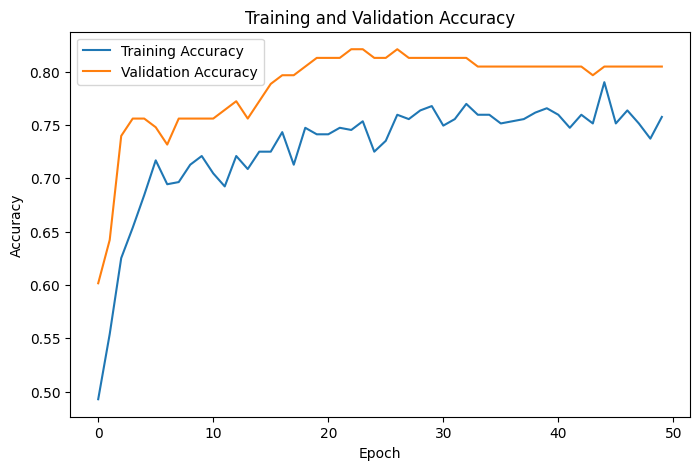

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [16]:
def create_grid_model(
    neurons=12,
    activation="relu",
    dropout_rate=0.2,
    learning_rate=0.001,
    kernel_initializer="uniform"
):

    model = Sequential()

    model.add(
        Dense(
            neurons,
            input_dim=8,
            activation=activation,
            kernel_initializer=kernel_initializer
        )
    )

    model.add(Dropout(dropout_rate))

    model.add(
        Dense(
            neurons,
            activation=activation,
            kernel_initializer=kernel_initializer
        )
    )

    model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation="sigmoid"))

    optimizer = Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [17]:
keras_model = KerasClassifier(
    model=create_grid_model,
    verbose=0
)

In [18]:
!pip install -q --upgrade scikit-learn scikeras

In [19]:
param_grid = {
    "batch_size": [10, 20],
    "epochs": [50, 100]
}

grid = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result = grid.fit(X_train, y_train)

print("Best Score:", grid_result.best_score_)
print("Best Parameters:", grid_result.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Score: 0.7687868643392317
Best Parameters: {'batch_size': 20, 'epochs': 50}


In [20]:
param_grid = {
    "batch_size": [10, 20],
    "epochs": [50, 100]
}

grid = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result = grid.fit(X_train, y_train)

print("Best Score:", grid_result.best_score_)
print("Best Parameters:", grid_result.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Score: 0.7622509166268133
Best Parameters: {'batch_size': 10, 'epochs': 100}


In [22]:
param_grid_lr = {
    "model__learning_rate": [0.001, 0.01],
    "epochs": [50],
    "batch_size": [20]
}

grid_lr = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid_lr,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result_lr = grid_lr.fit(X_train, y_train)

print("Best Learning Rate Score:", grid_result_lr.best_score_)
print("Best Learning Rate Parameters:", grid_result_lr.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Learning Rate Score: 0.7687709230033476
Best Learning Rate Parameters: {'batch_size': 20, 'epochs': 50, 'model__learning_rate': 0.001}


In [21]:
param_grid_init = {
    "model__kernel_initializer": ["uniform", "normal"],
    "epochs": [50],
    "batch_size": [20]
}

grid_init = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid_init,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result_init = grid_init.fit(X_train, y_train)

print("Best Initialization Score:", grid_result_init.best_score_)
print("Best Initialization Parameters:", grid_result_init.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Initialization Score: 0.7655268611509646
Best Initialization Parameters: {'batch_size': 20, 'epochs': 50, 'model__kernel_initializer': 'normal'}


In [23]:
param_grid_activation = {
    "model__activation": ["relu", "tanh"],
    "epochs": [50],
    "batch_size": [20]
}

grid_activation = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid_activation,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result_activation = grid_activation.fit(X_train, y_train)

print("Best Activation Score:", grid_result_activation.best_score_)
print("Best Activation Parameters:", grid_result_activation.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Activation Score: 0.7736410011158935
Best Activation Parameters: {'batch_size': 20, 'epochs': 50, 'model__activation': 'tanh'}


In [24]:
param_grid_dropout = {
    "model__dropout_rate": [0.0, 0.2, 0.4],
    "epochs": [50],
    "batch_size": [20]
}

grid_dropout = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid_dropout,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result_dropout = grid_dropout.fit(X_train, y_train)

print("Best Dropout Score:", grid_result_dropout.best_score_)
print("Best Dropout Parameters:", grid_result_dropout.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Dropout Score: 0.7720468675274988
Best Dropout Parameters: {'batch_size': 20, 'epochs': 50, 'model__dropout_rate': 0.0}


In [25]:
param_grid_neurons = {
    "model__neurons": [8, 12, 16, 20],
    "epochs": [50],
    "batch_size": [20]
}

grid_neurons = GridSearchCV(
    estimator=keras_model,
    param_grid=param_grid_neurons,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

grid_result_neurons = grid_neurons.fit(X_train, y_train)

print("Best Neurons Score:", grid_result_neurons.best_score_)
print("Best Neurons Parameters:", grid_result_neurons.best_params_)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Best Neurons Score: 0.7704128805993943
Best Neurons Parameters: {'batch_size': 20, 'epochs': 50, 'model__neurons': 20}


In [26]:
print("========== GRID SEARCH RESULTS ==========")

print("\n1. Batch Size and Epochs")
print("Best Score:", grid_result.best_score_)
print("Best Parameters:", grid_result.best_params_)

print("\n2. Learning Rate")
print("Best Score:", grid_result_lr.best_score_)
print("Best Parameters:", grid_result_lr.best_params_)

print("\n3. Weight Initialization")
print("Best Score:", grid_result_init.best_score_)
print("Best Parameters:", grid_result_init.best_params_)

print("\n4. Activation Function")
print("Best Score:", grid_result_activation.best_score_)
print("Best Parameters:", grid_result_activation.best_params_)

print("\n5. Dropout")
print("Best Score:", grid_result_dropout.best_score_)
print("Best Parameters:", grid_result_dropout.best_params_)

print("\n6. Number of Neurons")
print("Best Score:", grid_result_neurons.best_score_)
print("Best Parameters:", grid_result_neurons.best_params_)

========== GRID SEARCH RESULTS ==========

1. Batch Size and Epochs
Best Score: 0.7622509166268133
Best Parameters: {'batch_size': 10, 'epochs': 100}

2. Learning Rate
Best Score: 0.7687709230033476
Best Parameters: {'batch_size': 20, 'epochs': 50, 'model__learning_rate': 0.001}

3. Weight Initialization
Best Score: 0.7655268611509646
Best Parameters: {'batch_size': 20, 'epochs': 50, 'model__kernel_initializer': 'normal'}

4. Activation Function
Best Score: 0.7736410011158935
Best Parameters: {'batch_size': 20, 'epochs': 50, 'model__activation': 'tanh'}

5. Dropout
Best Score: 0.7720468675274988
Best Parameters: {'batch_size': 20, 'epochs': 50, 'model__dropout_rate': 0.0}

6. Number of Neurons
Best Score: 0.7704128805993943
Best Parameters: {'batch_size': 20, 'epochs': 50, 'model__neurons': 20}


In [27]:
best_model = grid_result.best_estimator_

print("Best model selected successfully!")
print("Best parameters:", grid_result.best_params_)

Best model selected successfully!
Best parameters: {'batch_size': 10, 'epochs': 100}


In [28]:
test_accuracy = best_model.score(X_test, y_test)

print("Best Model Test Accuracy:", test_accuracy)

Best Model Test Accuracy: 0.7467532467532467


In [29]:
final_predictions = best_model.predict(X_test)

print("Final predictions generated!")
print(final_predictions[:20])

Final predictions generated!
[1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 1 0]


In [30]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        final_predictions
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.84      0.81       100
           1       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154



In [31]:
final_cm = confusion_matrix(
    y_test,
    final_predictions
)

print("Confusion Matrix:")
print(final_cm)

Confusion Matrix:
[[84 16]
 [23 31]]


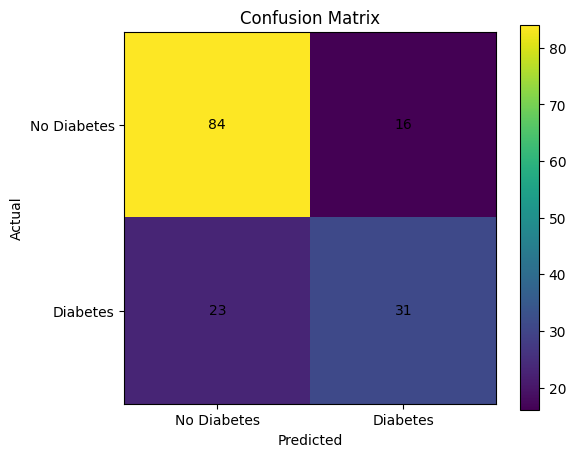

In [32]:
plt.figure(figsize=(6, 5))

plt.imshow(final_cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, final_cm[i, j],
                 ha="center",
                 va="center")

plt.show()

In [33]:
accuracy = accuracy_score(
    y_test,
    final_predictions
)

print("Final Accuracy:", accuracy)
print("Final Accuracy (%):", accuracy * 100)

Final Accuracy: 0.7467532467532467
Final Accuracy (%): 74.67532467532467
